In [43]:
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm

import numpy as np

from astropy import units as u
from astropy import constants as const
from astropy.io import fits
from astropy.visualization import simple_norm

In [9]:
x = 5 * u.km
x = x.to(u.m)

const.G
const.e
const.h
const.c
const.R

# How to open .fits file
# hdul=fits.open("example.fits")

<<class 'astropy.constants.codata2022.CODATA2022'> name='Gas constant' value=8.31446261815324 uncertainty=0.0 unit='J / (K mol)' reference='CODATA 2022'>

In [25]:
def ideal_gas_law(number_of_moles, volume, temperature):
    V = volume * (u.m ** 3)
    n = number_of_moles * u.mol
    R = const.R
    T = temperature * u.K
    pressure = (n / V) * R * T
    return pressure

In [26]:
with fits.open("spitzer_image.fits") as hdul:
    header = hdul[0].header
    data = hdul[0].data

data[np.isnan(data)] = 0

In [27]:
print(header["DATE"],
      header["EXPTIME"],
      header["NAXIS1"],
      header["NAXIS2"])

2006-12-02T01:06:10 1.2 1025 513


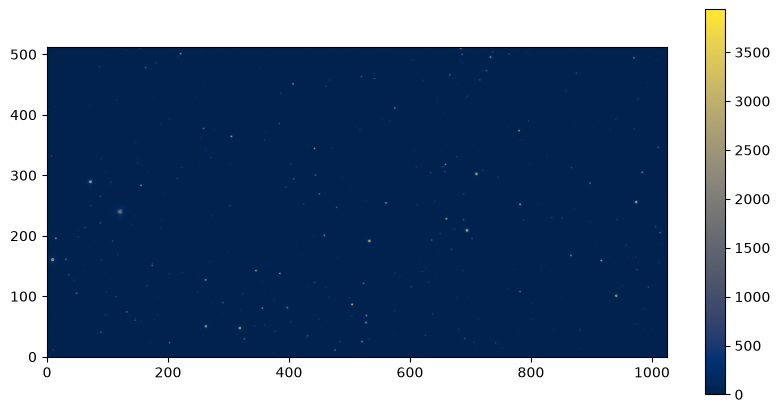

In [29]:
plt.figure(figsize=(10, 5))
plt.imshow(data, cmap = "cividis", origin = "lower")
plt.colorbar()
plt.show()

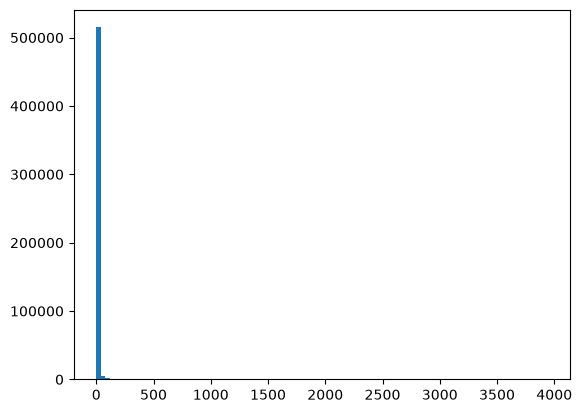

In [20]:
plt.hist(data.ravel(), bins = 100)
plt.show()

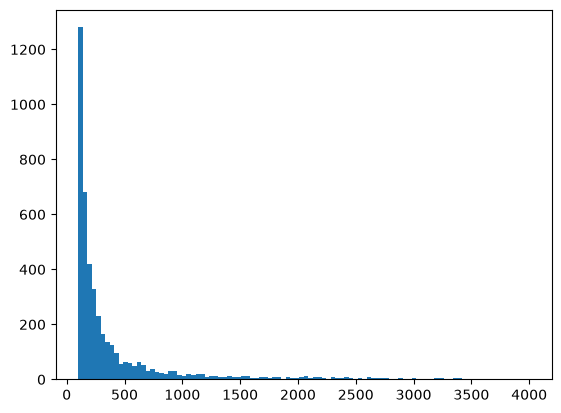

In [24]:
plt.hist(data.ravel(), bins = 100, range = (100, 4000))
plt.show()

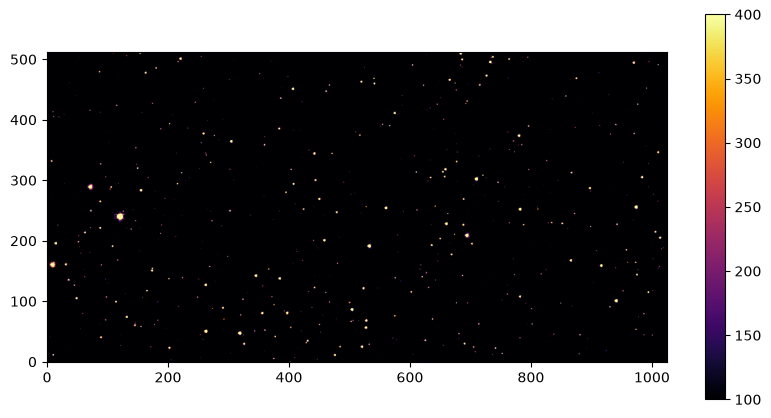

In [34]:
plt.figure(figsize=(10, 5))
plt.imshow(data, cmap = "inferno", origin = "lower", vmin = 100, vmax = 400)
plt.colorbar()
plt.show()

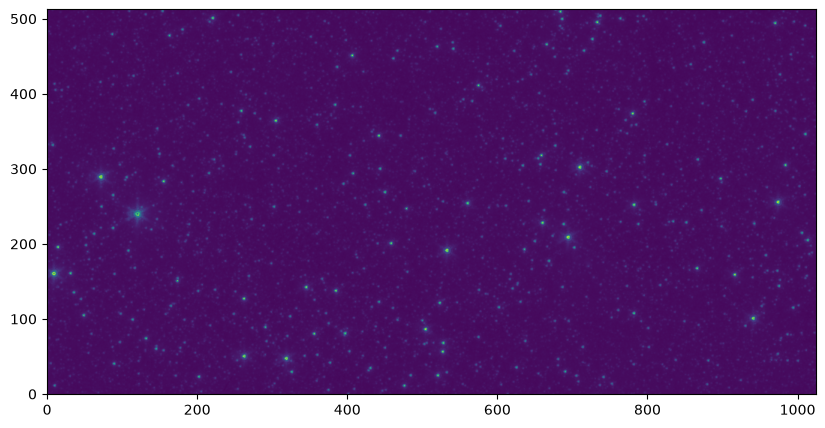

In [40]:
plt.figure(figsize = (10, 5))
norm = simple_norm(data, stretch="sqrt")
plt.imshow(data, cmap = "viridis", origin = "lower", norm = norm)
plt.show()